In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

In [2]:
L = tf.keras.layers

In [3]:
tr = pd.read_csv("mnist_train.csv")
te = pd.read_csv("mnist_test.csv")
Xtr,ytr = tr.drop(columns="label").values.reshape(-1,28,28,1) / 255, tr.label.values
Xte,yte = te.drop(columns="label").values.reshape(-1,28,28,1) / 255, te.label.values

In [4]:
model = tf.keras.Sequential([L.Conv2D(32, 3, activation="relu"), L.MaxPooling2D(), L.Conv2D(64, 3, activation="relu"), L.MaxPooling2D(),
                             L.Flatten(), L.Dense(128, activation="relu"), L.Dense(10, activation="softmax")])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h = model.fit(Xtr, ytr, epochs=5, batch_size=128, validation_data=(Xte, yte))

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8512 - loss: 0.5083 - val_accuracy: 0.9825 - val_loss: 0.0561
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9814 - loss: 0.0611 - val_accuracy: 0.9863 - val_loss: 0.0396
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9874 - loss: 0.0402 - val_accuracy: 0.9886 - val_loss: 0.0343
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9911 - loss: 0.0292 - val_accuracy: 0.9890 - val_loss: 0.0361
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9927 - loss: 0.0226 - val_accuracy: 0.9882 - val_loss: 0.0372


In [6]:
print(model.evaluate(Xte, yte))                                  
print(classification_report(yte, model.predict(Xte).argmax(1)))  

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9846 - loss: 0.0460
[0.037202633917331696, 0.9882000088691711]
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       1.00      1.00      1.00      1135
           2       0.98      1.00      0.99      1032
           3       1.00      0.98      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.99      0.98      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.96      0.99      0.98       974
           9       1.00      0.97      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



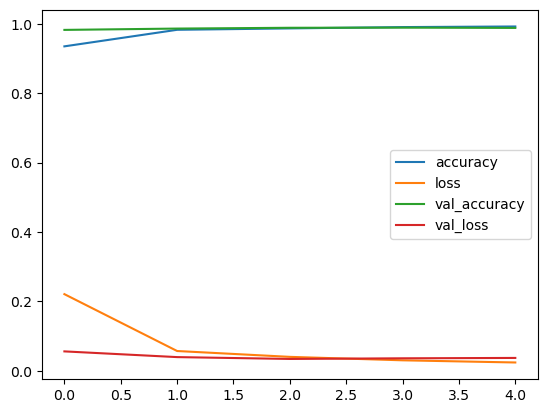

In [7]:
pd.DataFrame(h.history).plot(); 
plt.show()                       

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


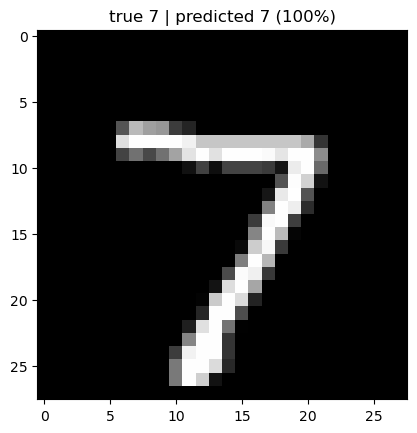

In [8]:
#one example
names = [str(k) for k in range(10)]
i = 0                                                          # any test image
p = model.predict(Xte[i:i+1])[0]                               # one probability per class
plt.imshow(Xte[i].squeeze(), cmap="gray"); plt.title(f"true {names[yte[i]]} | predicted {names[p.argmax()]} ({p.max():.0%})")
plt.show()